In [1]:
HEADPATH = '/home/gutil/scratch/2025-06-28_Manual-Drift-Recording/'
# HEADPATH = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/Drift-Correction/'
# Drift is Barcode data relative to experiment data
# i.e. how much do I have to move the experiment data to align it with the Barcode data

In [2]:
import napari
import numpy as np
from skimage import io

### Nd2 reader for experiment data


In [3]:
from nd2reader import ND2Reader
# import h5py
import numpy as np
import os

HEADPATH = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/Drift-Correction/'
nd2_filename = HEADPATH + 'Experiment_crop_XY-All_T-Last.nd2'
output_filename = HEADPATH + 'Experiment_crop_XY-All_T-Last_For-Drift.hdf5'

# Define the cropping parameters as variables
crop_x = 1000  # Replace with your desired top-left x-coordinate
crop_y = 600  # Replace with your desired top-left y-coordinate
crop_width = 400  # Replace with your desired width
crop_height = 550 # Replace with your desired height


In [ ]:

with ND2Reader(nd2_filename) as nd2file:
    # Get the number of views (positions) from the ND2 file metadata
    num_views = nd2file.sizes['v']
    print(f"Number of views in the ND2 file: {num_views}")
     # Determine the data type from the first frame to preallocate the array
    first_frame = nd2file.get_frame_2D(t=0, v=0)
    dtype = first_frame.dtype
    print(f"Data type of the first frame: {dtype}")

    # Preallocate the 3D NumPy array
    cropped_array_3D = np.empty((num_views, crop_height, crop_width), dtype=dtype)

    # Iterate through each view (since there is only one timepoint: t=0)
    for v in range(num_views):
        # Get the 2D frame for the current view at timepoint 0
        frame = nd2file.get_frame_2D(t=0, v=v)

        # Crop the image
        cropped_array_3D[v, :, :] = frame[crop_y:crop_y + crop_height, crop_x:crop_x + crop_width]

        print(f"Cropped image for view {v} and stored in array.")

In [4]:
output_filename

'/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/Drift-Correction/Experiment_crop_XY-All_T-Last_For-Drift.hdf5'

In [4]:
import h5py

In [6]:
# # Open the HDF5 file for writing
with h5py.File(output_filename, 'w') as hf:
    # Create a single dataset in the HDF5 file and write the 3D array
    hf.create_dataset('data', data=cropped_array_3D)
    print(f"Saved the 3D array to dataset 'data' in: {output_filename}")

print("Cropping, stacking, and saving to HDF5 complete.")

Saved the 3D array to dataset 'data' in: /home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/Drift-Correction/Experiment_crop_XY-All_T-Last_For-Drift.hdf5
Cropping, stacking, and saving to HDF5 complete.


In [5]:
import matplotlib.pyplot as plt

In [6]:
import h5py

In [4]:
EXPERIMENT_CROPPED_PATH = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/Drift-Correction/Experiment_crop_XY-All_T-Last_For-Drift.hdf5'

In [9]:
# open the HDF5 file to read the data
with h5py.File(EXPERIMENT_CROPPED_PATH, 'r') as hf:
    # Read the dataset
    data = hf['data'][:]
    print(f"Loaded data shape: {data.shape}, dtype: {data.dtype}")

Loaded data shape: (627, 550, 400), dtype: uint16


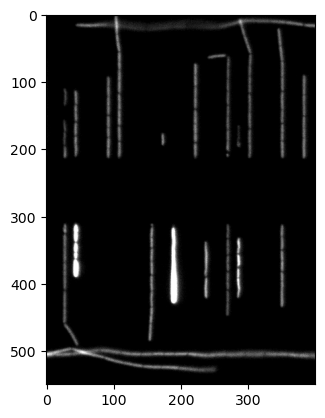

In [17]:
plt.imshow(data[400, :, :], cmap='gray', vmin=500, vmax=3000)

### Crop barcode data

In [26]:
headpath = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/'
headpath+'/run/'+'fov=100_config=BF_t=1.hdf5'

'/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01//run/fov=100_config=BF_t=1.hdf5'

In [27]:
HEADPATH = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/run/'
# nd2_filename = HEADPATH + 'Experiment_crop_XY-All_T-Last.nd2'
output_filename = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/Drift-Correction/' + 'Barcodes_crop_XY-All_T-01_For-Drift.hdf5'

In [32]:
filename_pattern = 'fov=*_config=Cy5_t=0.hdf5'
import glob
# Find all files matching the pattern
file_list = glob.glob(os.path.join(HEADPATH, filename_pattern))
# Sort the file list to ensure consistent ordering accounting for numbers
file_list.sort(key=lambda x: int(x.split('fov=')[1].split('_')[0])) 
print(len(file_list), "files found matching the pattern.")

627 files found matching the pattern.


In [33]:
with h5py.File(file_list[0], 'r') as hf:
    # Determine the data type from the first file to preallocate the array
    # first_frame = hf['data'][:]
    first_frame = hf['data'][:]
    dtype = first_frame.dtype
    print(f"Data type of the first frame: {dtype}")

# Preallocate the 3D NumPy array
num_views = len(file_list)
assert num_views == 627

cropped_array_3D = np.empty((num_views, crop_height, crop_width), dtype=dtype)
# Iterate through each file and read the data
for v, file_path in enumerate(file_list):
    with h5py.File(file_path, 'r') as hf:
        # Read the dataset
        frame = hf['data'][:]
        # Crop the image
        cropped_array_3D[v, :, :] = frame[crop_y:crop_y + crop_height, crop_x:crop_x + crop_width]
        print(f"Cropped image for view {v} and stored in array.")

Data type of the first frame: uint16
Cropped image for view 0 and stored in array.
Cropped image for view 1 and stored in array.
Cropped image for view 2 and stored in array.
Cropped image for view 3 and stored in array.
Cropped image for view 4 and stored in array.
Cropped image for view 5 and stored in array.
Cropped image for view 6 and stored in array.
Cropped image for view 7 and stored in array.
Cropped image for view 8 and stored in array.
Cropped image for view 9 and stored in array.
Cropped image for view 10 and stored in array.
Cropped image for view 11 and stored in array.
Cropped image for view 12 and stored in array.
Cropped image for view 13 and stored in array.
Cropped image for view 14 and stored in array.
Cropped image for view 15 and stored in array.
Cropped image for view 16 and stored in array.
Cropped image for view 17 and stored in array.
Cropped image for view 18 and stored in array.
Cropped image for view 19 and stored in array.
Cropped image for view 20 and sto

In [34]:
output_filename = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/Drift-Correction/' + 'Barcodes_crop_XY-All_T-01_For-Drift_Cy5.hdf5'
print(output_filename)

/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/Drift-Correction/Barcodes_crop_XY-All_T-01_For-Drift_Cy5.hdf5


In [35]:
# # Open the HDF5 file for writing
with h5py.File(output_filename, 'w') as hf:
    # Create a single dataset in the HDF5 file and write the 3D array
    hf.create_dataset('data', data=cropped_array_3D)
    print(f"Saved the 3D array to dataset 'data' in: {output_filename}")

print("Cropping, stacking, and saving to HDF5 complete.")

Saved the 3D array to dataset 'data' in: /home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01/Drift-Correction/Barcodes_crop_XY-All_T-01_For-Drift_Cy5.hdf5
Cropping, stacking, and saving to HDF5 complete.


In [51]:
# # open the HDF5 file to read the data
with h5py.File(output_filename, 'r') as hf:
    # Read the dataset
    data = hf['data'][:]
    print(f"Loaded data shape: {data.shape}, dtype: {data.dtype}")

Loaded data shape: (627, 550, 400), dtype: uint16


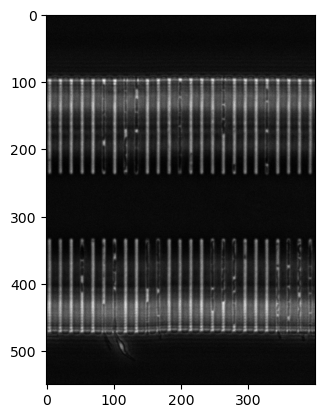

In [53]:
plt.imshow(data[0, :, :], cmap='gray')

In [ ]:
# Load all files
for v in range(num_views):